# Lightcones on disk

`py21cmfast.run_lightcone` and `tuesday`'s `construct_lightcone_from_cache` build a
lightcone in memory. For a large box, or many lightcones of one run, that may not fit,
and a job that stops loses its work. `make_lightcones_on_disk` instead writes each
lightcone of each quantity to its own HDF5 file while it reads the coeval boxes of a run
from its cache, one interval between node redshifts at a time. Each file records which
intervals are filled, so a later call fills only what is left, and a call made while the
simulation is still running can fill the intervals whose boxes exist.

This tutorial shows:

* making lightcones on disk, and reading them (`LightconeStore`);
* resuming, and filling a lightcone while the run is not finished;
* the dv/dr correction of the brightness temperature (`include_dvdr_on_disk`), and a file
  that 21cmFAST reads as a `LightCone` (`link_lightcone_file`);
* redshift-space distortions (`rsd_lightconer` and `apply_rsds_on_disk`), for
  rectilinear and angular lightcones, and their caveats.

In [1]:
import tempfile
from pathlib import Path

import astropy.units as un
import numpy as np
import py21cmfast as p21c
from py21cmfast.drivers.lightcone import AngularLightcone
from py21cmfast.io.caching import OutputCache, RunCache

from tuesday.core import lc2slice_y, plot_healpix_map, plot_lightcone_slice
from tuesday.core.lightcones import LightconeStore
from tuesday.simulators.py21cmfast.lightconers import FastAngularLightconer
from tuesday.simulators.py21cmfast.lightcones import (
    CachedFields,
    apply_rsds_on_disk,
    construct_lightcone_from_cache,
    include_dvdr_on_disk,
    link_lightcone_file,
    make_lightcones_on_disk,
    rsd_lightconer,
)

## A small simulation

As in the tutorial on angular lightcones, we run a small box (64 cells of 3 Mpc on a
side) with node redshifts from 12 to 6, and keep its 3D velocities. Its boxes go to a
cache, which is all that the lightcones on disk read.

In [2]:
inputs = p21c.InputParameters.from_template(
    "simple", random_seed=12, node_redshifts=np.arange(12.0, 5.9, -0.5)
).evolve_input_structs(BOX_LEN=192, HII_DIM=64, DIM=192, KEEP_3D_VELOCITIES=True)
cell = inputs.simulation_options.cell_size
box_length = inputs.simulation_options.BOX_LEN * un.Mpc
cosmo = inputs.cosmo_params.cosmo

cache = OutputCache(tempfile.mkdtemp())
p21c.run_lightcone(
    lightconer=p21c.RectilinearLightconer.between_redshifts(
        min_redshift=6.5, max_redshift=11.0, resolution=cell
    ),
    inputs=inputs,
    cache=cache,
    write=True,
    progressbar=False,
)
run = RunCache.from_inputs(inputs, cache)

## Making lightcones on disk

`make_lightcones_on_disk` takes the lightconers by name, the quantities, the run's cache
and a directory. It makes one pass over the node redshifts, from high to low redshift,
reads only the fields the lightcones need, and makes the slices with each lightconer's
own `make_lightcone_slices`, so the lightcones are those of 21cmFAST. Any lightconer
works; here a rectilinear one and a HEALPix one (see the tutorial on angular lightcones).
The files are `out/<name>/<quantity>.h5`.

In [3]:
between = {"min_redshift": 6.5, "max_redshift": 11.0, "resolution": cell, "cosmo": cosmo}
lightconers = {
    "rect": p21c.RectilinearLightconer.between_redshifts(**between),
    "healpix": FastAngularLightconer.healpix(16, subsample_level=1, **between),
}
out = Path(tempfile.mkdtemp())
paths = make_lightcones_on_disk(lightconers, ["brightness_temp", "density"], run, out)
sorted(str(p.relative_to(out)) for by_q in paths.values() for p in by_q.values())

['healpix/brightness_temp.h5',
 'healpix/density.h5',
 'rect/brightness_temp.h5',
 'rect/density.h5']

A `LightconeStore` opens one file. `lightcone` is an h5py dataset (slices on the last
axis), so parts of it can be read without reading the rest. The store also holds the
distances and redshifts of the slices, the node redshifts, the mean of the quantity's box
at each node redshift that was read, and which intervals between node redshifts are
filled. `plot_lightcone_slice` of `tuesday.core` plots a plane of the rectilinear
lightcone.

shape: (64, 64, 405) complete: True
intervals filled: [ True  True  True  True  True  True  True  True  True  True  True  True]
global mean at z = 9.0 : 17.682018280029297


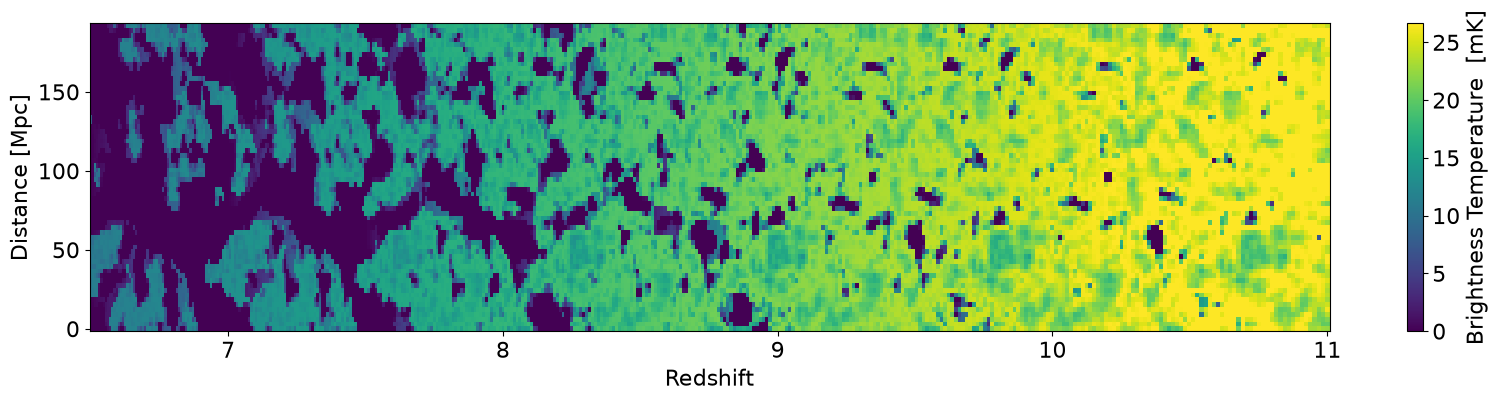

In [4]:
with LightconeStore.open(paths["rect"]["brightness_temp"]) as store:
    print("shape:", store.shape, "complete:", store.complete)
    print("intervals filled:", store.done)
    print("global mean at z =", store.node_redshifts[6], ":", store.global_mean[6])
    redshifts = store.redshifts
    plane = store.lightcone[:, 32:33, :]  # reads one plane of the lightcone

plot_lightcone_slice(
    plane * un.mK, box_length, redshifts, transform2slice=lc2slice_y(idx=0), cmap="viridis"
);

The HEALPix store holds one map per slice, which `plot_healpix_map` plots.

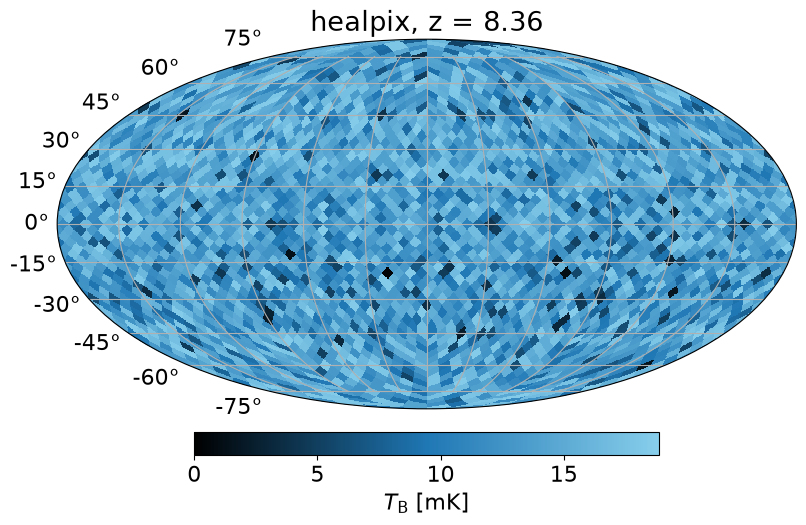

In [5]:
with LightconeStore.open(paths["healpix"]["brightness_temp"]) as store:
    i = store.shape[-1] // 2
    sky = store.lightcone[:, i]  # reads one map
    z_i = store.redshifts[i]

plot_healpix_map(sky * un.mK, 16, title=f"healpix, z = {z_i:.2f}");

The lightcones equal those that `construct_lightcone_from_cache` makes in memory.

In [6]:
import attrs

for name, lightconer in lightconers.items():
    in_memory = construct_lightcone_from_cache(
        run, attrs.evolve(lightconer, quantities=("brightness_temp",))
    )
    with LightconeStore.open(paths[name]["brightness_temp"]) as store:
        print(name, np.array_equal(store.lightcone[()], in_memory.lightcones["brightness_temp"]))

rect True


healpix True


## Resuming, and runs that are not finished

Calling `make_lightcones_on_disk` again with the same arguments fills only the intervals
that are not filled yet. Before it writes anything, it works out which intervals are
left and whether the boxes they need are cached. If a box is missing it raises an error,
unless `partial=True`, in which case it fills the intervals whose boxes are there and
leaves the others (NaN) for a later call.

To show this without stopping a simulation, we read the cache through a `CachedFields`
that does not see the boxes below z = 8, as if the run had not reached them yet. Any
object with the members of `CachedFields` (`inputs`, `node_redshifts`, `has`, `read`) can
be the source.

In [7]:
class Unfinished(CachedFields):
    # The cache of a run that has not reached z = 8 yet.

    def has(self, redshift, fields):
        return redshift >= 8 and super().has(redshift, fields)


later = Path(tempfile.mkdtemp())
try:
    make_lightcones_on_disk(lightconers, "brightness_temp", Unfinished(run), later)
except FileNotFoundError as error:
    print(error)
print("files written:", list(later.iterdir()))

['brightness_temp'] are not cached at 3 node redshifts (7.5 to 6.5); use partial=True to fill the intervals whose boxes are cached
files written: []


In [8]:
make_lightcones_on_disk(lightconers, "brightness_temp", Unfinished(run), later, partial=True)
with LightconeStore.open(later / "rect" / "brightness_temp.h5") as store:
    print("node redshifts:   ", store.node_redshifts)
    print("intervals filled: ", store.done)
    print("complete:", store.complete)
    filled = ~np.isnan(store.lightcone[0, 0, :])
    print(f"{filled.sum()} of {filled.size} slices filled")

node redshifts:    [12.  11.5 11.  10.5 10.   9.5  9.   8.5  8.   7.5  7.   6.5  6. ]
intervals filled:  [ True  True  True  True  True  True  True  True False False False  True]
complete: False
237 of 405 slices filled


The intervals from z = 8 to 6.5 are left empty. The last interval, from 6.5 to 6, has no
slices of these lightcones, so it counts as filled.

Once the run is finished, the same call (without the stand-in source) fills the rest and
reads only the boxes it needs. The files then equal those made in one go. Changing a
lightconer (e.g. its directions) between calls raises an error instead of mixing two
lightcones in one file; `clobber=True` starts the files again.

In [9]:
make_lightcones_on_disk(lightconers, "brightness_temp", run, later)
with (
    LightconeStore.open(later / "rect" / "brightness_temp.h5") as resumed,
    LightconeStore.open(paths["rect"]["brightness_temp"]) as once,
):
    print("complete:", resumed.complete)
    print("same as in one go:", np.array_equal(resumed.lightcone[()], once.lightcone[()]))

complete: True
same as in one go: True


## The dv/dr correction, and a file for 21cmFAST

By default, `run_lightcone` returns the brightness temperature with the velocity-gradient
(dv/dr) correction. `include_dvdr_on_disk` applies the same correction
(`py21cmfast.rsds.include_dvdr_in_tau21`) to the stores `brightness_temp`,
`los_velocity` and, with `USE_TS_FLUCT`, `tau_21` of one lightconer, and writes
`brightness_temp_dvdr.h5`. The correction differentiates the velocity along each line of
sight, so it works in blocks of lines of sight that fit in `max_memory`. It needs slices
one cell apart.

`link_lightcone_file` then writes one file per lightconer with the layout of 21cmFAST's
lightcone files. Its lightcones are HDF5 links to the stores, so nothing is copied, and
`LightCone.from_file` (or `AngularLightcone.from_file`) reads it. As in the output of
`run_lightcone`, `brightness_temp` is the corrected field and `brightness_temp_no_dvdr`
the one without the correction.

In [10]:
make_lightcones_on_disk(lightconers, "los_velocity", run, out)
for name in lightconers:
    include_dvdr_on_disk(out / name, inputs)

lightcone = p21c.LightCone.from_file(link_lightcone_file(out / "rect", inputs))
print(sorted(lightcone.lightcones))
print(sorted(lightcone.global_quantities))

reference = construct_lightcone_from_cache(
    run,
    attrs.evolve(lightconers["rect"], quantities=("brightness_temp",)),
    include_dvdr_in_tau21=True,
)
corrected = lightcone.lightcones["brightness_temp"]
diff = np.abs(corrected - reference.lightcones["brightness_temp"]).max()
print(f"largest difference from 21cmFAST / largest value: {diff / np.abs(corrected).max():.1e}")

['brightness_temp', 'brightness_temp_no_dvdr', 'density', 'los_velocity']
['brightness_temp', 'density']


largest difference from 21cmFAST / largest value: 5.1e-08


## Redshift-space distortions

RSDs move the field along the line of sight by its peculiar velocity, so the slices near
the ends of a lightcone take in the field from beyond them. `run_lightcone` with
`apply_rsds=True` therefore makes the lightcone on more distances than requested, applies
the RSDs, and trims the result. On disk these are separate steps:

1. `rsd_lightconer(lightconer, inputs)` returns the lightconer on the distances that
   `run_lightcone` uses (estimated from the rms velocity given by CLASS), with the same
   directions and quantities. It works for rectilinear and angular lightconers.
2. `make_lightcones_on_disk` with it, including `los_velocity`, and
   `include_dvdr_on_disk` as above.
3. `apply_rsds_on_disk` writes `<quantity>_with_rsds.h5` for the given stores. Give
   `"brightness_temp_dvdr"` for the corrected brightness temperature, as `run_lightcone`
   applies the RSDs after the correction.
4. `link_lightcone_file(..., lc_distances=...)` with the requested distances records the
   extra slices as buffers, which `LightCone.from_file` leaves out.

Here we do this for a rectilinear lightcone and for an angular one (a ring). Each call
to `rsd_lightconer` runs CLASS, which takes a few seconds; `classy_output` reuses a run.

In [11]:
n = 1024
ring = FastAngularLightconer.between_redshifts(
    latitude=np.zeros(n), longitude=np.linspace(0, 2 * np.pi, n, endpoint=False), **between
)
requested = {"rect": lightconers["rect"], "ring": ring}
extended = {f"{name}_rsd": rsd_lightconer(lc, inputs) for name, lc in requested.items()}
for name, lc in requested.items():
    d, e = lc.lc_distances, extended[f"{name}_rsd"].lc_distances
    print(f"{name}: {d.min():.0f} - {d.max():.0f} requested, {e.min():.0f} - {e.max():.0f} made")

make_lightcones_on_disk(extended, ["brightness_temp", "los_velocity"], run, out)
for name in extended:
    include_dvdr_on_disk(out / name, inputs)
    apply_rsds_on_disk(out / name, inputs, ["brightness_temp_dvdr"])

rect_lc = p21c.LightCone.from_file(
    link_lightcone_file(out / "rect_rsd", inputs, lc_distances=lightconers["rect"].lc_distances)
)
ring_lc = AngularLightcone.from_file(
    link_lightcone_file(out / "ring_rsd", inputs, lc_distances=ring.lc_distances)
)
sorted(ring_lc.lightcones)

rect: 8628 Mpc - 9840 Mpc requested, 8625 Mpc - 9843 Mpc made
ring: 8628 Mpc - 9840 Mpc requested, 8625 Mpc - 9843 Mpc made


['brightness_temp',
 'brightness_temp_no_dvdr',
 'brightness_temp_with_rsds',
 'los_velocity']

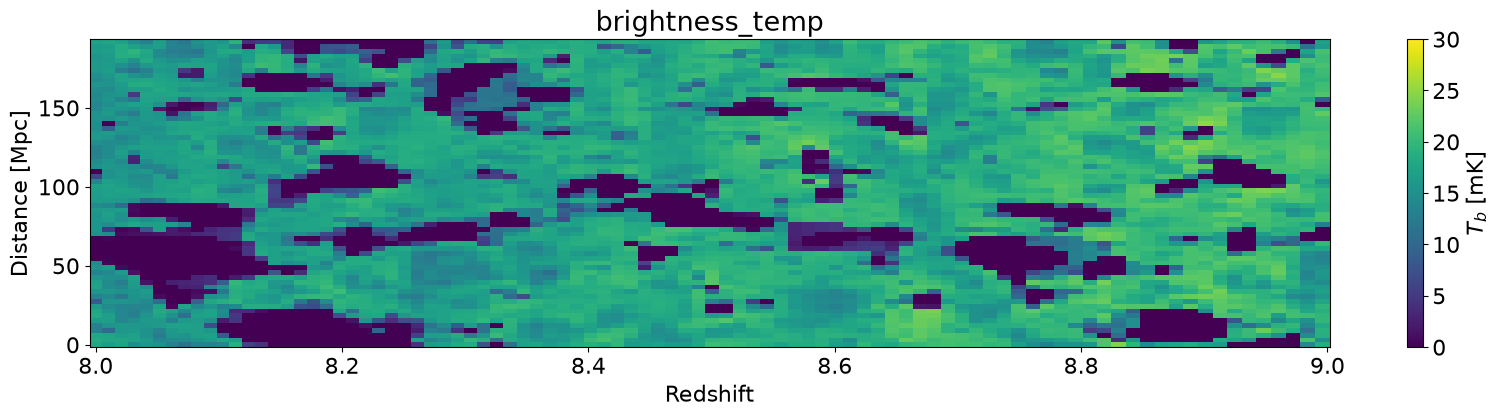

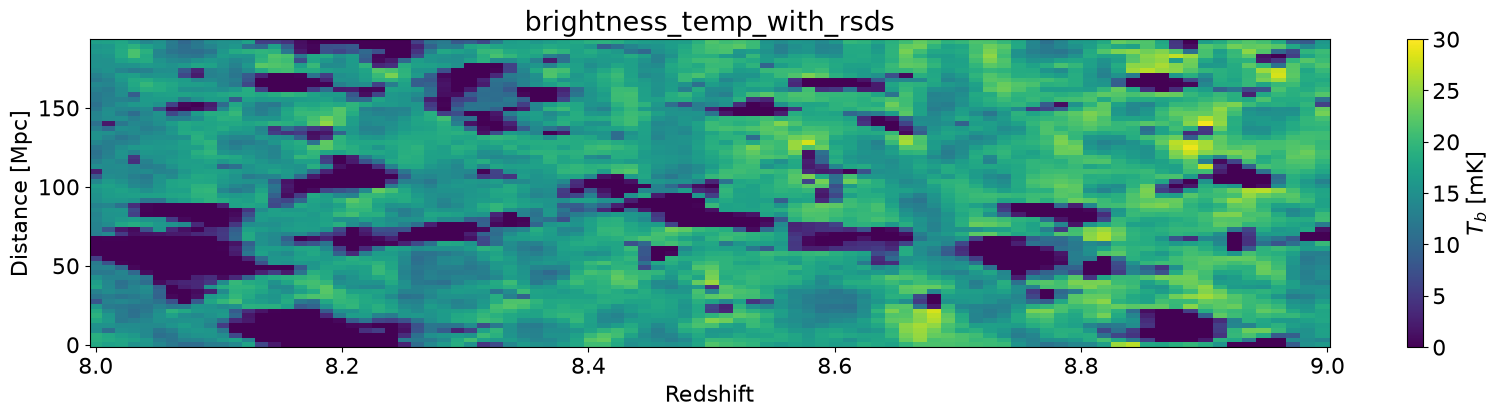

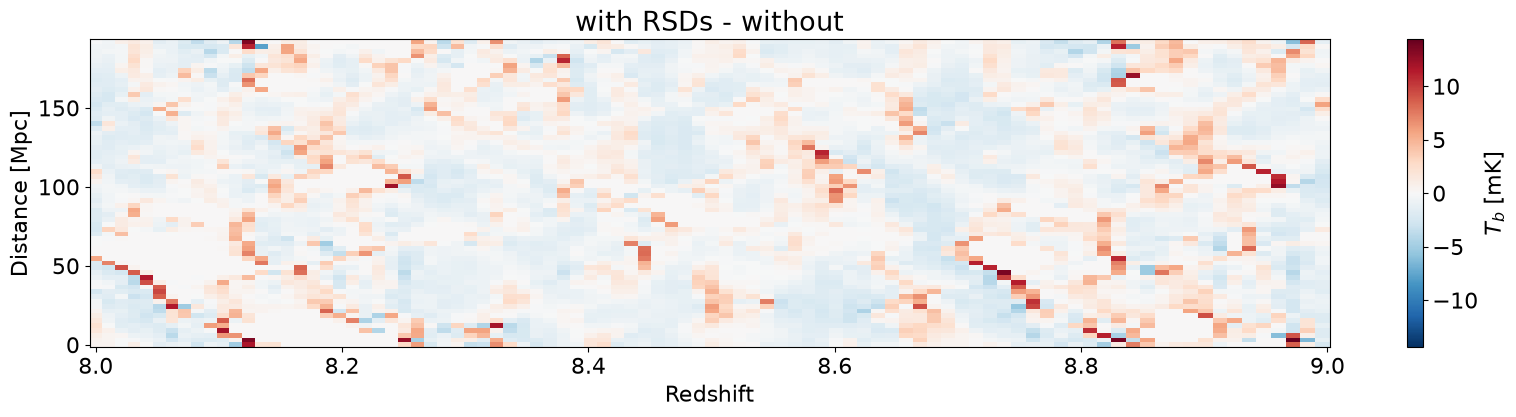

In [12]:
z = rect_lc.lightcone_redshifts
zoom = (z > 8) & (z < 9)
parts = {
    key: rect_lc.lightcones[key][..., zoom] * un.mK
    for key in ("brightness_temp", "brightness_temp_with_rsds")
}
parts["with RSDs - without"] = parts["brightness_temp_with_rsds"] - parts["brightness_temp"]

for title, part in parts.items():
    if title.startswith("with"):
        limit = np.abs(part[:, 32]).max().value
        style = {"cmap": "RdBu_r", "vmin": -limit, "vmax": limit}
    else:
        style = {"cmap": "viridis", "vmin": 0, "vmax": 30}
    plot_lightcone_slice(
        part,
        box_length,
        z[zoom],
        transform2slice=lc2slice_y(idx=32),
        title=title,
        clabel=r"$T_b$ [mK]",
        **style,
    )

The figure shows one plane of the rectilinear lightcone between z = 8 and 9. Both
lightcones equal those that 21cmFAST makes in memory with the same options:

In [13]:
for name, lc in {"rect": rect_lc, "ring": ring_lc}.items():
    reference = construct_lightcone_from_cache(
        run, requested[name], include_dvdr_in_tau21=True, apply_rsds=True, n_rsd_subcells=4
    )
    same = np.allclose(lc.lightcone_distances, requested[name].lc_distances)
    print(f"{name}: distances as requested: {same}")
    for key in ("brightness_temp", "brightness_temp_with_rsds"):
        ref = reference.lightcones[key]
        diff = np.abs(lc.lightcones[key] - ref).max() / np.abs(ref).max()
        print(f"  {key:26s} largest difference / largest value: {diff:.1e}")

rect: distances as requested: True
  brightness_temp            largest difference / largest value: 5.3e-08
  brightness_temp_with_rsds  largest difference / largest value: 1.4e-07


ring: distances as requested: True
  brightness_temp            largest difference / largest value: 3.0e-08
  brightness_temp_with_rsds  largest difference / largest value: 1.3e-07


Some things to keep in mind:

* As in `run_lightcone`, the extended lightconer has slices one cell apart, starting a
  whole number of cells below the lowest requested distance. If the requested slices are
  one cell apart, as here, the result has the requested slices. Otherwise it has the
  slices of the extended lightconer that lie within the requested range.
* `rsd_lightconer` sets the extra distances from the rms velocity given by CLASS, as
  21cmFAST does: the rms of the full velocity for an angular lightconer, and of the
  component along the line of sight for a rectilinear one.
* The node redshifts must reach beyond the lightcone by the distance the RSDs need;
  otherwise `rsd_lightconer` raises 21cmFAST's error.
* The dv/dr correction and the RSDs assume slices one cell apart, and refuse other
  spacings.
* An angular lightcone needs `KEEP_3D_VELOCITIES=True`. Its `los_velocity` is the 3D
  velocity projected on each direction, and the RSDs move the field along each line of
  sight.
* With pixels that average sub-samples (e.g. HEALPix sub-pixels), the dv/dr correction
  and the RSDs are applied to the averaged pixels, as in `run_lightcone`.
* `apply_rsds_on_disk` and `run_lightcone` divide each cell into 4 sub-cells by default
  (`n_rsd_subcells`), and `construct_lightcone_from_cache` into 10. Give the same value
  to compare them.
* `apply_rsds_on_disk` takes about 110 bytes per value of the lightcone and per
  sub-cell (`n_rsd_subcells`, 4 by default), and works in blocks of lines of sight that
  fit in `max_memory`. With the default chunks of the stores, whole chunks need about
  9 GB with 4 sub-cells; smaller blocks read each chunk more than once.